In [5]:
!pip install linearmodels


/tmp/ipykernel_1848/3016812282.py:104: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  ).fit(cov_type="HC1")
/usr/local/lib/python3.13/dist-packages/linearmodels/panel/model.py:1258: MissingValueWarning: 
Inputs contain missing values. Dropping rows with missing observations.
  super().__init__(dependent, exog, weights=weights, check_rank=check_rank)
/tmp/ipykernel_1848/3016812282.py:143: AbsorbingEffectWarning: 
Variables have been fully absorbed and have removed from the regression:

health

  model4 = PanelOLS(y_fe, X_fe, entity_effects=True, drop_absorbed=True).fit(



                   Baseline OLS + Work Ethic Interaction
--------------------------------------------------------
Intercept          3.516***     2.975***     3.152***   
                   (0.085)      (0.094)      (0.091)    
                   (0.068)      (0.068)      (0.067)    
                   (0.062)      (0.062)      (0.059)    
                   (0.062)      (0.062)      (0.055)    
                   (0.056)      (0.057)      (0.043)    
                   (0.066)      (0.066)      (0.060)    
                   (0.067)      (0.067)      (0.071)    
                   (0.064)      (0.064)      (0.055)    
                   (0.069)      (0.069)      (0.071)    
                   (0.061)      (0.061)      (0.054)    
                   (0.061)      (0.061)      (0.052)    
                   (0.060)      (0.060)      (0.052)    
                   (0.061)      (0.061)      (0.047)    
                   (0.061)      (0.061)      (0.052)    
                   (0.065)    

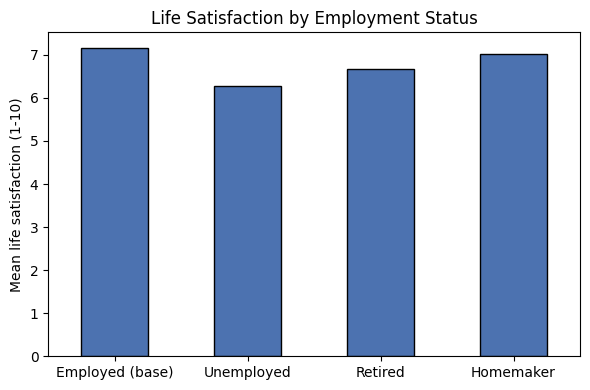

In [6]:
"""
employment_life_satisfaction.py

Python translation of `New_one_.do`.

Analyses the relationship between employment status and life satisfaction
in a cross-country panel. Produces:
  - Table 1: pooled descriptive statistics
  - Table 2: four regression models (three pooled OLS + one fixed-effects panel)
  - A summary bar chart of mean life satisfaction by employment status

STATA -> Python "Rosetta stone" used throughout this script:

    STATA                                   Python
    -----                                   ------
    use file.dta, clear                     pd.read_stata("file.dta")
    encode var, gen(new)                    df["new"] = df["var"].astype("category").cat.codes
                                             (kept as category dtype for i.var-style dummies)
    gen new = a * b                         df["new"] = df["a"] * df["b"]
    reg y x1 x2 i.group, robust             smf.ols("y ~ x1 + x2 + C(group)", data=df)
                                                 .fit(cov_type="HC1")
    xtset id time                           df = df.set_index(["id", "time"])
    xtreg y x1 x2, fe robust                PanelOLS(y, X, entity_effects=True)
                                                 .fit(cov_type="robust")
    eststo / esttab                         statsmodels.iolib.summary2.summary_col(...)
    estpost tabstat ..., stats(...)         df[vars].describe().T

Requirements (install once):
    pip install pandas statsmodels matplotlib linearmodels
"""

import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from statsmodels.iolib.summary2 import summary_col
from linearmodels.panel import PanelOLS

# --------------------------------------------------------------------------
# 0. CONFIGURATION
# --------------------------------------------------------------------------
# STATA: use panel_clean.dta, clear
DATA_PATH = "panel_clean.dta"          # point this at your .dta file
TABLE1_PATH = "Table1_Descriptive.csv"
TABLE2_PATH = "Table2_Regression.csv"
FIGURE_PATH = "life_satisfaction_by_status.png"


# --------------------------------------------------------------------------
# 1. LOAD DATA
# --------------------------------------------------------------------------
# pandas reads .dta files natively -- no separate import/export step needed,
# and column labels/value labels come along with `convert_categoricals=True`
# (pandas' default), which is the closest analogue to STATA's labelled data.
df = pd.read_stata(DATA_PATH)


# --------------------------------------------------------------------------
# 2. DATA PREPARATION
# --------------------------------------------------------------------------
# STATA: encode s003, gen(country)
# `encode` turns a string variable into an integer-coded categorical with
# the string values preserved as labels. In pandas we do the same with
# `.astype("category")`, which keeps the original string labels (unlike
# `.cat.codes`, which would throw them away and just give you plain
# integers). Passing the *categorical* column into the regression formula
# lets statsmodels build the `i.country` dummy set for us -- see Section 3.
df["country"] = df["s003"].astype("category")

# STATA: gen unemp_x_norm = unemployed * country_work_ethic
df["unemp_x_norm"] = df["unemployed"] * df["country_work_ethic"]


# --------------------------------------------------------------------------
# 3. POOLED OLS MODELS (Models 1-3)
# --------------------------------------------------------------------------
# STATA: eststo clear
#        eststo model1: reg y x1 x2 ... i.country, robust
#
# `smf.ols` takes an R-style formula string. `C(country)` is the formula
# equivalent of STATA's `i.country` -- it expands the categorical variable
# into a full set of dummy variables (one omitted as the reference group)
# automatically, so you never build dummy columns by hand.
#
# `cov_type="HC1"` requests heteroskedasticity-robust standard errors --
# STATA's `, robust` option uses the same HC1 estimator by default for `reg`.

model1 = smf.ols(
    "life_satisfaction ~ unemployed + retired + homemaker "
    "+ health + female + age + age_sq + education + married + income + C(country)",
    data=df,
).fit(cov_type="HC1")

model2 = smf.ols(
    "life_satisfaction ~ unemployed + retired + homemaker + work_ethic "
    "+ health + female + age + age_sq + education + married + income + C(country)",
    data=df,
).fit(cov_type="HC1")

model3 = smf.ols(
    "life_satisfaction ~ unemployed + unemp_x_norm + country_work_ethic "
    "+ retired + homemaker + work_ethic + health + female + age + age_sq "
    "+ education + married + income + C(country)",
    data=df,
).fit(cov_type="HC1")
# Note: if `country_work_ethic` varies only by country (not by year), it is
# a linear combination of the `C(country)` dummies and this model is
# collinear -- statsmodels will print a "rank-deficient" warning instead of
# STATA's silent "omitted because of collinearity" message. If you see that
# warning, either drop `C(country)` from model3 or drop the standalone
# `country_work_ethic` term, matching whichever variable STATA dropped.


# --------------------------------------------------------------------------
# 4. FIXED-EFFECTS PANEL MODEL (Model 4)
# --------------------------------------------------------------------------
# STATA: xtset respid year
#        xtreg y x1 x2 ..., fe robust
#
# `xtset` in STATA just declares the panel structure; in pandas the
# equivalent is setting a MultiIndex of (entity, time) on the dataframe.
# `linearmodels.PanelOLS` is the direct analogue of `xtreg, fe`: passing
# `entity_effects=True` demeans out the respondent-level fixed effect,
# exactly like STATA's within transformation.
panel_df = df.set_index(["respid", "year"])

fe_vars = ["unemployed", "retired", "homemaker", "work_ethic", "health", "income"]
y_fe = panel_df["life_satisfaction"]
X_fe = panel_df[fe_vars]
# add_constant is optional with entity_effects (the FE absorbs the mean),
# but PanelOLS still needs an intercept column if you want one reported.

# `drop_absorbed=True` mirrors STATA's automatic handling of time-invariant
# regressors under `xtreg, fe`: any variable that doesn't vary within a
# respondent (e.g. a trait measured once) is perfectly absorbed by the
# entity effect and STATA silently omits it. linearmodels raises an error
# by default instead of dropping silently, so we opt in to the STATA-like
# behaviour explicitly.
#
# `cov_type="clustered", cluster_entity=True` clusters standard errors by
# respondent -- the standard choice for panel data, since it allows for
# arbitrary within-respondent serial correlation over time (rather than
# just heteroskedasticity, which `cov_type="robust"` alone would cover).
model4 = PanelOLS(y_fe, X_fe, entity_effects=True, drop_absorbed=True).fit(
    cov_type="clustered", cluster_entity=True
)


# --------------------------------------------------------------------------
# 5. TABLE 2 -- COMBINED REGRESSION TABLE
# --------------------------------------------------------------------------
# STATA: esttab model1 model2 model3 model4 using "Table2_Regression.rtf", ///
#            b(3) se(3) star(...) label mtitles(...) drop(*.country) note(...)
#
# `summary_col` is statsmodels' closest built-in equivalent to `esttab`:
# it lines several fitted models up side by side with stars for
# significance. It only accepts statsmodels result objects, so model4
# (a linearmodels result) is reported separately underneath -- this is a
# known gap versus STATA, where `esttab` handles both `reg` and `xtreg`
# results uniformly.
#
# `drop(*.country)` in STATA suppresses the country dummy rows from the
# printed table. The equivalent here is filtering them out of the combined
# results before printing, since summary_col does not have a native
# "drop by pattern" option.

combined = summary_col(
    [model1, model2, model3],
    stars=True,
    float_format="%0.3f",
    model_names=["Baseline OLS", "+ Work Ethic", "Interaction"],
    info_dict={"N": lambda x: f"{int(x.nobs)}"},
)

# Strip out the C(country)[...] dummy rows, mirroring `drop(*.country)`
combined.tables[0] = combined.tables[0][
    ~combined.tables[0].index.str.contains(r"C\(country\)", regex=True)
]

print(combined)
print("\nModel 4 (Fixed Effects, entity-demeaned) -- reported separately:")
print(model4.summary)

# Save Table 2 to disk. STATA writes a formatted .rtf; the closest
# lightweight equivalent for further editing in Word/Excel is a .csv of
# the coefficient table, which is what we export here.
combined.tables[0].to_csv(TABLE2_PATH)
print(f"\nSaved Table 2 coefficients to {TABLE2_PATH}")


# --------------------------------------------------------------------------
# 6. TABLE 1 -- DESCRIPTIVE STATISTICS
# --------------------------------------------------------------------------
# STATA: estpost tabstat var1 var2 ..., stats(n mean sd min max) columns(stats)
#        esttab using "Table1_Descriptive.rtf", cells("count mean sd min max")
#
# pandas' `.describe()` gives count/mean/std/min/25%/50%/75%/max in one call;
# we select just the five columns STATA's `tabstat` reported to match the
# original table layout exactly.
desc_vars = [
    "life_satisfaction", "unemployed", "retired", "homemaker", "work_ethic",
    "country_work_ethic", "health", "female", "age", "education", "married",
    "income",
]

table1 = df[desc_vars].describe().T[["count", "mean", "std", "min", "max"]]
table1.columns = ["N", "Mean", "Std. Dev.", "Min", "Max"]
table1 = table1.round(2)
table1["N"] = table1["N"].astype(int)

print("\nTable 1: Summary Statistics (Pooled Panel)")
print(table1)
table1.to_csv(TABLE1_PATH)
print(f"Saved Table 1 to {TABLE1_PATH}")


# --------------------------------------------------------------------------
# 7. FIGURE -- LIFE SATISFACTION BY EMPLOYMENT STATUS
# --------------------------------------------------------------------------
# Not present in the original .do file, but included since matplotlib was
# requested: a quick visual companion to Table 2's coefficients, showing
# raw (unconditional) mean life satisfaction for each employment group.
status_means = pd.Series(
    {
        "Employed (base)": df.loc[
            (df["unemployed"] == 0) & (df["retired"] == 0) & (df["homemaker"] == 0),
            "life_satisfaction",
        ].mean(),
        "Unemployed": df.loc[df["unemployed"] == 1, "life_satisfaction"].mean(),
        "Retired": df.loc[df["retired"] == 1, "life_satisfaction"].mean(),
        "Homemaker": df.loc[df["homemaker"] == 1, "life_satisfaction"].mean(),
    }
)

fig, ax = plt.subplots(figsize=(6, 4))
status_means.plot(kind="bar", ax=ax, color="#4C72B0", edgecolor="black")
ax.set_ylabel("Mean life satisfaction (1-10)")
ax.set_title("Life Satisfaction by Employment Status")
ax.set_xticklabels(status_means.index, rotation=0)
fig.tight_layout()
fig.savefig(FIGURE_PATH, dpi=150)
print(f"Saved figure to {FIGURE_PATH}")

plt.show()